# CT4110 – Topic 7 Assignment Solutions
## Simon's Algorithm

This notebook contains worked solutions for the two Simon tasks and the classical period-finding scaling task. Qiskit prints bit strings in highest-index-first order.

In [1]:
try:
    import qiskit
    import qiskit_aer
except ImportError:
    %pip install -q qiskit qiskit-aer matplotlib pylatexenc

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

simulator = AerSimulator()
print("Qiskit setup complete.")

Qiskit setup complete.


## Task 1 solution – Construct the two-qubit oracle

The table defines $f(x_1x_0)=0(x_1\oplus x_0)$ in the displayed big-endian order. The first output bit, shown on the left, remains zero. The second output bit, shown on the right, stores the XOR of the two input bits. In the lecture's top-to-bottom wire order, output qubits are `q2, q3`, so the two controlled-X gates target output qubit `q3`.

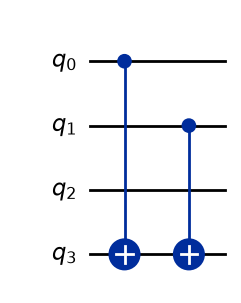

In [2]:
def task1_oracle():
    oracle = QuantumCircuit(4, name="U_f task 1")
    oracle.cx(0, 3)
    oracle.cx(1, 3)
    return oracle

task1_oracle().draw("mpl")

{'11': 528, '00': 472}


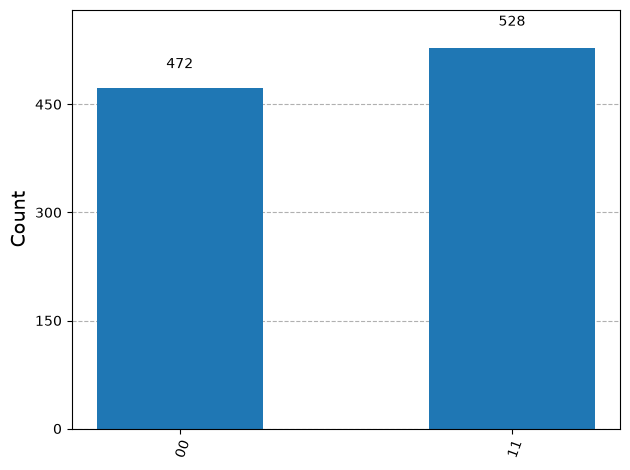

In [3]:
task1_qc = QuantumCircuit(4, 2)
task1_qc.h([0, 1])
task1_qc.append(task1_oracle(), range(4))
task1_qc.h([0, 1])
task1_qc.measure([0, 1], [0, 1])

# Reverse the measured circuit. Quantum and classical wires move together,
# so no manual classical-bit rewiring is needed.
task1_big_endian = task1_qc.reverse_bits()

task1_big_endian.draw("mpl")

compiled_task1 = transpile(task1_big_endian, simulator)
task1_counts = simulator.run(compiled_task1, shots=1000).result().get_counts()
print(task1_counts)
plot_histogram(task1_counts)

In [4]:
# TASK 1 DECODING – PEN-AND-PAPER SOLUTION
# No programmatic equation solver is required.
#
# Measured nonzero outcome: 11
# After reverse_bits(), the outcome is read from left to right as Z0 Z1.
# Equation: Z0*S0 + Z1*S1 = 0 (mod 2).
# For Z0 Z1 = 11: S0 + S1 = 0 (mod 2).
# Therefore S0 = S1. Simon's promise excludes 00, so S0 S1 = 11.

## Task 2 solution – Complete the three-qubit algorithm

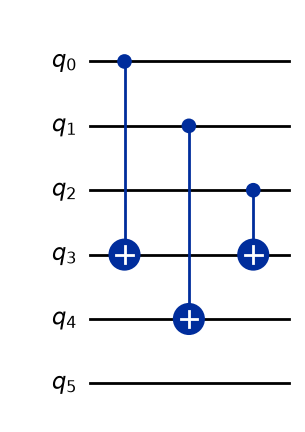

In [5]:
def task2_oracle():
    oracle = QuantumCircuit(6, name="U_f task 2")
    oracle.cx(0, 3)
    oracle.cx(2, 3)
    oracle.cx(1, 4)
    return oracle

task2_oracle().draw("mpl")

{'111': 490, '000': 476, '101': 514, '010': 520}


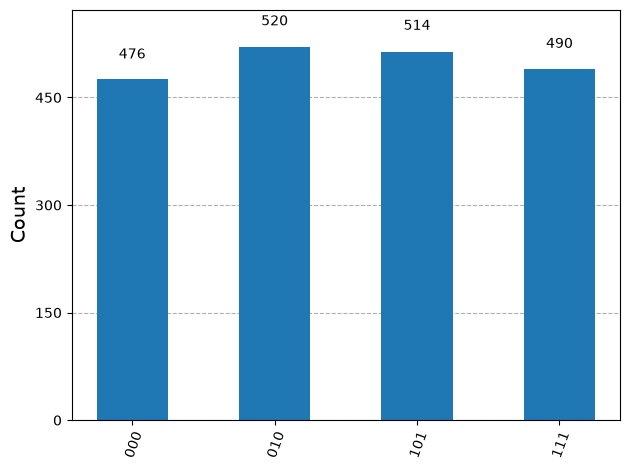

In [6]:
task2_qc = QuantumCircuit(6, 3)
task2_qc.h([0, 1, 2])
task2_qc.append(task2_oracle(), range(6))
task2_qc.h([0, 1, 2])
task2_qc.measure([0, 1, 2], [0, 1, 2])

# Reverse the measured circuit so quantum and classical wires move together.
task2_big_endian = task2_qc.reverse_bits()

task2_big_endian.draw("mpl")

compiled_task2 = transpile(task2_big_endian, simulator)
task2_counts = simulator.run(compiled_task2, shots=2000).result().get_counts()
print(task2_counts)
plot_histogram(task2_counts)

In [7]:
# TASK 2 DECODING – PEN-AND-PAPER SOLUTION
# No programmatic equation solver is required.
#
# After reverse_bits(), outcomes are read from left to right as Z0 Z1 Z2,
# and the hidden string is written as S0 S1 S2.
# Choose independent nonzero outcomes 010 and 101.
# The equation is Z0*S0 + Z1*S1 + Z2*S2 = 0 (mod 2).
# From 010: S1 = 0.
# From 101: S0 + S2 = 0 (mod 2), so S0 = S2.
# Excluding 000 gives the hidden string S0 S1 S2 = 101.
# The possible outcomes orthogonal to 101 are 000, 010, 101 and 111.
# These are exactly the outcomes shown by the histogram.

## Task 3 solution – Classical period finding and its scaling

For $\gcd(a,N)=1$, the direct method generates $a^1,a^2,\ldots$ modulo $N$ and stops at the first return to 1. Each iteration first performs ordinary multiplication and then applies modulo reduction to that product. Its work equals the order $r$. In the worst case $r$ can be $N-1$, which is approximately $2^n$ for an $n$-bit modulus.

In [8]:
from math import gcd

def classical_order(a, N):
    if gcd(a, N) != 1:
        raise ValueError("a and N must be coprime")
    value = 1
    number_of_multiplications = 0
    for r in range(1, N + 1):
        previous_value = value

        # Piece 1: ordinary multiplication
        product = previous_value * a

        number_of_multiplications += 1

        # Piece 2: reduce the product modulo N
        value = product % N
        if value == 1:
            return r, number_of_multiplications
    raise RuntimeError("No order found")

period_5_21, multiplications_5_21 = classical_order(5, 21)
print("period of 5 modulo 21:", period_5_21)
print("number of multiplications:", multiplications_5_21)

period of 5 modulo 21: 6
number of multiplications: 6


  a        N   bits     period    multiplications
  2        9      4          6                  6
  2       25      5         20                 20
  3       49      6         42                 42
  2      121      7        110                110
  2      243      8        162                162
  2      361      9        342                342
  3      961     10        930                930
  3     1849     11       1806               1806
  2     3721     12       3660               3660
  3     7921     13       7832               7832
  3    16129     14      16002              16002
  2    32761     15      32580              32580
  6    63001     16      62750              62750


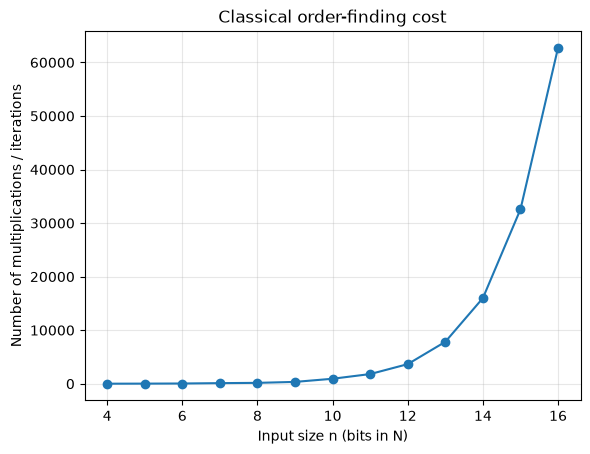

In [9]:
import matplotlib.pyplot as plt

cases = [
    (2, 9),       # 4-bit modulus
    (2, 25),      # 5-bit modulus
    (3, 49),      # 6-bit modulus
    (2, 121),     # 7-bit modulus
    (2, 243),     # 8-bit modulus
    (2, 361),     # 9-bit modulus
    (3, 961),     # 10-bit modulus
    (3, 1849),    # 11-bit modulus
    (2, 3721),    # 12-bit modulus
    (3, 7921),    # 13-bit modulus
    (3, 16129),   # 14-bit modulus
    (2, 32761),   # 15-bit modulus
    (6, 63001),   # 16-bit modulus
]

bit_lengths = []
multiplication_counts = []
results = []
for a, N in cases:
    period, number_of_multiplications = classical_order(a, N)
    n = N.bit_length()
    bit_lengths.append(n)
    multiplication_counts.append(number_of_multiplications)
    results.append((a, N, n, period, number_of_multiplications))

print(f"{'a':>3} {'N':>8} {'bits':>6} {'period':>10} {'multiplications':>18}")
for a, N, n, period, count in results:
    print(f"{a:>3} {N:>8} {n:>6} {period:>10} {count:>18}")

plt.plot(bit_lengths, multiplication_counts, "o-")
plt.xlabel("Input size n (bits in N)")
plt.ylabel("Number of multiplications / iterations")
plt.title("Classical order-finding cost")
plt.grid(alpha=0.3)
plt.show()

### Task 3 interpretation

1. The direct search tests each successive exponent once. Each test contains an ordinary multiplication followed by a separate modulo reduction. Reaching the first return at exponent $r$ therefore takes exactly $r$ multiplication-and-modulo steps.
2. For the 16-bit composite modulus $N=63001$ with $a=6$, the period and measured cost are 62,750 multiplications.
3. The exact period depends on $a$ and $N$, so the table cannot predict one precise 32-bit count. The worst-case $O(2^n)$ trend places a difficult 32-bit case on the scale of billions of multiplications.
4. The horizontal axis measures the number of bits, not the value of $N$. Adding one bit can double $N$ and therefore double the worst-case order. A cost proportional to $N$ is consequently exponential in $n=\lceil\log_2N\rceil$.
5. Simon's problem has XOR repetition, $f(x)=f(x\oplus s)$. Order finding has additive repetition in the exponent, $f(k)=a^k\bmod N$ and $f(k+r)=f(k)$, with $a^r=1\pmod N$.